# Lecture 18 - Natural Language Processing

[![View notebook on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.ipynb)
[![View on Website](https://img.shields.io/static/v1.svg?logo=quarto&label=Web&message=View%20on%20Website&color=blue)](https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/Lectures/Theme_3-Model_Engineering/Lecture_18-NLP/Lecture_18-NLP.html)

<a id='top'></a>

- [18.1 Introduction to NLP](#18.1-introduction-to-nlp)
- [18.2 Preprocessing Text Data](#18.2-preprocessing-text-data)
    - [18.2.1 Text Standardization](#18.2.1-text-standardization)
    - [18.2.2 Tokenization](#18.2.2-tokenization)
- [18.3 Representation of Text Data](#18.3-representation-of-text-data)
    - [18.3.1 Set Models Approach](#18.3.1-set-models-approach)
    - [18.3.2 Sequence Models Approach](#18.3.2-sequence-models-approach)
        - [One-Hot Word Vector Representation](#one-hot-word-vector-representation)
        - [Word Embeddings](#word-embeddings)
- [18.4 Introduction to Hugging Face](#18.4-introduction-to-hugging-face)
- [18.5 Tokenizers](#18.5-tokenizers)
    - [18.5.1 Tokenizing Text](#18.5.1-tokenizing-text)
    - [18.5.2 Special Tokens and Subwords](#18.5.2-special-tokens-and-subwords)
    - [18.5.3 Padding and Truncation](#18.5.3-padding-and-truncation)
- [18.6 Datasets](#18.6-datasets)
    - [18.6.1 Loading the Emotions Dataset](#18.6.1-loading-the-emotions-dataset)
    - [18.6.2 Applying a Tokenizer to a Dataset](#18.6.2-applying-a-tokenizer-to-a-dataset)
- [18.7 Models](#18.7-models)
    - [18.7.1 Importing a Pretrained Model](#18.7.1-importing-a-pretrained-model)
    - [18.7.2 Fine-tuning a Pretrained Model](#18.7.2-fine-tuning-a-pretrained-model)
- [18.8 Text Generation Strategies](#18.8-text-generation-strategies)
    - [18.8.1 Search-based Methods](#18.8.1-search-based-methods)
    - [18.8.2 Sampling-based Methods](#18.8.2-sampling-based-methods)
- [18.9 NLP Pipelines](#18.9-nlp-pipelines)
    - [18.9.1 Sentiment Analysis](#18.9.1-sentiment-analysis)
    - [18.9.2 Text Generation](#18.9.2-text-generation)
    - [18.9.3 Named Entity Recognition](#18.9.3-named-entity-recognition)
    - [18.9.4 Zero-shot Classification](#18.9.4-zero-shot-classification)
    - [18.9.5 Mask Filling](#18.9.5-mask-filling)
- [Appendix: Emotion Classification with an Embedding Model](#appendix:-emotion-classification-with-an-embedding-model)
- [References](#references)

<a id="18.1-introduction-to-nlp"></a>

## 18.1 Introduction to NLP

**Natural Language Processing (NLP)** is a branch of Computer Science (and more broadly, a branch of Artificial Intelligence) that is concerned with providing computers with the ability to understand texts and human language.

Common tasks in NLP include:

- *Text classification* — assign a class label to text based on the topic discussed in the text, e.g., sentiment analysis (positive or negative movie review), spam detection, content filtering (detect abusive content).
- *Text summarization/reading comprehension* — summarize a long input document with a shorter text.
- *Speech recognition* — convert spoken language to text.
- *Machine translation* — convert text in a source language to a target language.
- *Part of Speech (PoS) tagging* — mark up words in text as nouns, verbs, adverbs, etc.
- *Question answering* — output an answer to an input question.
- *Dialog generation* — generate the next reply in a conversation given the history of the conversation.
- *Text generation* — generate text to complete the sentence or to complete the paragraph.

Until recently, each of these tasks was solved with a separate, specialized model trained on task-specific data. Large Language Models (LLMs) have changed this: a single pretrained model can perform most of the above tasks, either directly from a text prompt or after a fine-tuning on a small dataset.

In this lecture, we will first cover the basic concepts for converting text into a numerical form that Machine Learning models can process. Afterward, we will introduce the Hugging Face platform, and we will use it to tokenize text, load datasets, fine-tune a pretrained model, generate text, and build pipelines for NLP tasks.

<a id="18.2-preprocessing-text-data"></a>

## 18.2 Preprocessing Text Data

Before text data can be processed by NLP models, it must first be converted into a numerical representation.

Converting text into numerical form typically involves the following steps:

- *Standardization* - remove punctuation, convert the text to lowercase letters.
- *Tokenization* - break the text into smaller units called tokens (e.g., individual words, individual characters, several consecutive words, etc.).
- *Indexing* - assign a unique numerical index to each token in the training set (i.e., build a vocabulary).
- *Embedding* - (used in more recent models) assign a numerical vector to each token that represents it in a continuous vector space. Examples include one-hot encoding and word embeddings.

Note that unlike conventional NLP models that employ the text preprocessing steps listed above, LLMs typically apply minimal text processing and standardization, such as removing irregular spacing in text, removing non-textual content (e.g., code, HTML tags), and removing unsafe or low-quality text content. Therefore, text preprocessing for LLM training focuses mainly on data cleanliness, and not on linguistic simplification.

<a id="18.2.1-text-standardization"></a>

### 18.2.1 Text Standardization
**Text standardization** usually includes several steps, which depend on the specific application. The steps involve:

- Remove punctuation marks (such as comma, period) or non-alphabetic characters (@, #, {, ]).
- Change all words to lowercase letters, since ML models should consider *Text* and *text* as the same word.

Some NLP tasks apply additional steps, such as:

- Correct spelling errors, or replace abbreviations with full words.
- Remove stop words, such as *for*, *the*, *is*, *to*, *some*, etc.; if the task is text classification, these words are not relevant to the meaning of the text.
- Apply stemming and lemmatization, which transform words to their base form, such as changing the word *driving* to *drive*, or *grilled* to *grill* since they have a common root.

Applying text standardization is helpful for training ML models, for example, because the models do not need to consider *Text* and *text* as two different words, which reduces the requirements for large training datasets. However, depending on the application, text standardization may remove information that can be important for some tasks, and this should always be considered when performing text preprocessing.

<a id="18.2.2-tokenization"></a>

### 18.2.2 Tokenization
**Tokenization** is breaking up a sequence of text into individual units called *tokens*.

Tokenization can be performed at different levels:

- *Character-level tokenization* - the text is divided into individual characters, and each character is a token, including letters, digits, punctuation marks, and symbols. One disadvantage of this type of tokenization is that anagrams (words with the same letters in different order, such as *silent* and *listen*) can have the same numerical encoding, which can affect the performance of ML models. In addition, character-level tokenization does not capture the semantic meaning of words as effectively as word-level tokens. Consequently, it is not widely used in practice.
- *Word-level tokenization* - each word in the text is a token. This type of tokenization provides a natural representation of input text with the words as building blocks of language, and it is commonly used.
- *Subword-level tokenization* - the words are divided into smaller units (e.g., tokenizing the word "unhappiness" into two tokens "un" + "happiness"). This type of tokenization is very common in recent Large Language Models. Also, in some languages with complex word structures, subword-level tokenization is the most suitable.
- *N-gram tokenization* - N consecutive words represent a token. For instance, N-grams consisting of two adjacent words are called bigrams, or three words constitute a trigram, etc. N-gram tokens preserve the word order and can potentially capture more information in the text. For instance, for spam filtering using bigram tokens such as *mailing list* or *bank account* may provide more helpful information than using word-level tokens.

For some NLP tasks, tokenization can also be performed at other levels of text. An example is sentence-level tokenization for the task of document segmentation into sentences.

An example of text standardization, word-level tokenization, and indexing is shown in the next figure.

<img src="images/tokenization.png" width="500">

*Figure: Text standardization, word-level tokenization, and indexing.*

Note also that in modern LLMs, subword tokenizers are not defined by hand, but are learned from a large text corpus. The most common algorithms are *Byte-Pair Encoding (BPE)* used by the GPT family of models, Llama, and most recent LLMs, *WordPiece* used by BERT, and *Unigram/SentencePiece* used by T5 and multilingual models. These tokenizers start from a vocabulary of individual characters (or bytes) and repeatedly merge the most frequent adjacent pairs of tokens, until the vocabulary reaches a predefined size, which is typically between 30,000 and 150,000 tokens. As a result, frequent words end up as single tokens, while rare words are split into several subword tokens, so that almost any text can be encoded without out-of-vocabulary words (see an example in Section 18.5.2). We will work with such tokenizers in Section 18.5.

<a id="18.3-representation-of-text-data"></a>

## 18.3 Representation of Text Data

Representation of groups of words in Machine Learning models for text processing is based on two general categories of approaches:

- **Set models** approach: the text is represented as an unordered collection of words. Such approaches include *bag-of-words* models.
- **Sequence models** approach: the text is represented as ordered sequences of words. These methods preserve the order of the words in the text. Representatives of these approaches are Recurrent Neural Networks and Transformer Networks.

The order of words in natural language is not necessarily fixed, and sentences with different orders of the words can have the same meaning. Also, different languages use different ways to order the words. As a result, defining the order of the words in text in NLP tasks is not straightforward.

<a id="18.3.1-set-models-approach"></a>

### 18.3.1 Set Models Approach

**Bag-of-words** models discard the information about the order of the words, where the term *bag* implies that the structure of the text is lost. A depiction of a bag-of-words is shown below, where the initial text is separated into word-level tokens, and a bag is created from all words in the text. Also, instead of individual words, these models often employ N-gram representations. These models typically consider the frequency of occurrence of each word in the training data, and a classifier is trained by using the word counts as inputs.

For instance, to create a spam filtering classifier, two bags-of-words can be created from the words in spam and non-spam emails. Presumably, the spam bag will contain trigger words (such as cheap, buy, stock) more frequently than the bag with words from non-spam emails. A classifier will be trained using the two bags-of-words and learn to differentiate trigger words from regular words. After the training, the classifier will analyze the words in new unseen messages, and predict the probability that these words belong to the spam or non-spam bag-of-words.

<img src="images/bag_of_words.png" width="600">

*Figure: Bag-of-words representation.*

The early applications of machine learning in NLP relied on bag-of-words models. Modern applications, especially those related to Large Language Models, rely predominantly on sequence models.

<a id="18.3.2-sequence-models-approach"></a>

### 18.3.2 Sequence Models Approach

**Sequence models** preserve the order of words in the input text. A typical implementation of sequence models includes representing the words in text data with integer indices, mapping the integers to vector representations, and passing the vectors to a machine learning model, where the layers in the model will account for the ordering of input vectors.

The input vectors to sequence models can be in the form of:

- One-hot word vector representation, or
- Word embeddings representation.

#### One-Hot Word Vector Representation

**One-hot word vector** representation is similar to encoding categorical features with one-hot encoding matrix. That is, the index for each word is converted to a one-hot vector, having `1 (hot)` for that word and `0 (cold)` for all other words. An example is shown in the left-hand figure, where we created a zero vector with length of 4, and assigned 1 for the index that corresponds to each word. Another example is shown in the right-hand figure.

<img src="images/one_hot_encodding.png" width="800">

*Figure: One-hot word vector encoding.*

One-hot word vector representation is not an efficient way to represent text, because for large text datasets the input vectors can become quite large. For instance, a training set with 20,000 words will need to use one-hot vectors of size 20,000 to represent each word, which results in slow training and requires a lot of memory.

Using word embeddings is more efficient, since the vectors for word representation are much smaller than the size of the vocabulary, and more importantly, embedding vectors can capture important semantic meaning of the words. Hence, most modern NLP models rely on word embeddings for representing words in text.

#### Word Embeddings

**Word embeddings** representation is used to convert each word into a vector (also referred to as *embedding vector*), in such a way that the embedding vectors of words that have similar semantic meaning have close spatial positions in the embeddings space.

The embeddings space consists of the set of vectors, where each word in the vocabulary is represented with one vector. For calculating the distance between the vectors in the embeddings space, typically cosine similarity is used as a distance metric. For two vectors $u$ and $v$, *cosine similarity* is calculated as the dot (scalar, inner) product of the vectors divided by the product of the norms of the vectors, i.e., $\dfrac{u\cdot v}{||u||\cdot ||v||}$.

Typical dimensionality of vectors for representing word embeddings in NLP models has been between 256 and 1,024. In modern LLMs, the dimensionality of token embeddings is commonly between 2,048 and 7,168. For instance, the following figure shows the embedding vector for the word 'work'. The embedding vector has many values, and each value represents some aspect of the meaning of that word.

<img src="images/embedding_vector.png" width="700">

*Figure: Embedding vector for the word 'work'.* Source: [link](https://ig.ft.com/generative-ai/)


The embedding vectors of words that have similar meanings are also similar. In the following figure, we can see that the embedding vectors of the words 'football' and 'soccer' are more similar to each other than the embedding vectors of the words 'sea' or 'we'.

<img src="images/embeddings_comparison.png" width="500">

*Figure: Embedding vectors for words with similar meanings are also similar.* Source: [link](https://ig.ft.com/generative-ai/)


A simple example of word embeddings space is shown below, where similar words are positioned closer to each other. Therefore, the spatial distance between the vectors is dependent on the semantic meaning of the words.

<img src="images/word_embeddings.png" width="500">

*Figure: Word embeddings space.* Source: [link](https://ig.ft.com/generative-ai/)


Two popular methods for generating word embeddings are *word2vec* and *GloVe*. These methods use Neural Networks to learn embedding vectors from a large corpus of text. The resulting vectors learned by these techniques can be imported as pretrained word embeddings and applied to downstream tasks with smaller training datasets.

For example, the website [Embedding Projector](http://projector.tensorflow.org) provides visualizations of word embeddings, and for an entered word displays other words that are adjacent in the embeddings space.

In the Appendix, an example is presented that uses the PyTorch embedding layer in a model for text classification.

<a id="18.4-introduction-to-hugging-face"></a>

## 18.4 Introduction to Hugging Face

**Hugging Face** ([link](https://huggingface.co/)) is a platform for Machine Learning and AI created in 2016, with the aim to "build, train, and deploy state of the art models powered by the reference open source in machine learning". Since then, Hugging Face has established itself as the main source for NLP and other Machine Learning tasks, providing open access to over 2 million pretrained models, datasets, and pertinent tools and resources. Hugging Face focuses on community-building around open-source machine learning tools and data. They also developed several [courses](https://huggingface.co/learn) on how to use their libraries for various tasks. Also note that while open access is provided to the core NLP libraries, Hugging Face also offers paid options for enterprise features, hosted inference endpoints, and the AutoTrain service for no-code model training.

The core Hugging Face libraries include Transformer models, Tokenizers, Datasets, and Accelerate. The Accelerate library enables distributed training with hardware acceleration devices, such as using multiple GPUs, or cloud accelerators with TPUs. In addition to these core libraries, Hugging Face provides various community resources, which include a platform for sharing models, code versioning, and Spaces for sharing apps developed with Hugging Face libraries and browsing apps created by others.

<img src="images/hf_libraries.png" width="400">

*Figure: Hugging Face libraries.*

The key characteristics of these libraries include:

- Ease of use and simplicity, where downloading and using state-of-the-art NLP models can be done with a few lines of code.
- Flexibility, since all models in the Transformers library are implemented as PyTorch `nn.Module` objects (earlier versions of the library also provided TensorFlow and JAX implementations for some models, but recent versions focus on PyTorch only).

<a id="18.5-tokenizers"></a>

## 18.5 Tokenizers

Hugging Face provides a **Tokenizers** library for converting raw text into sequences of tokens. The provided tokenizer functions perform text standardization, tokenization, and indexing.

When we use a pretrained NLP model from Hugging Face, our text data needs to be preprocessed in the same way as the training data used with the model. Therefore, we will need to download the tokenizer for that specific model. Access to pretrained models is provided through the `transformers` library and the [Hugging Face Hub](https://huggingface.co/models).

The `transformers` library by Hugging Face is preinstalled in Google Colab. If you don't run this notebook in Google Colab, you will need to first install the library with `pip install transformers`.

Let's consider the model DistilBERT, which is stored under the name `"distilbert-base-uncased"` in the Hugging Face Hub. It is a version of the BERT transformer model that takes case-insensitive English text as input data (therefore, uncased). To use the tokenizer for this model, we will first import it from the `transformers` package, and next we will download it from the Hugging Face Hub with the `AutoTokenizer` class and its method `from_pretrained()`. The argument `model_ckpt` is short for model checkpoint, and it stores the name of the pretrained model.

In [1]:
from transformers import AutoTokenizer

model_ckpt = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

The code loads the tokenizer associated with that model, including its vocabulary, tokenization rules, and configuration settings. Note that this code does not load the weights for model "distilbert-base-uncased". Loading the weights will be explained in a later section in the lecture.

The `AutoTokenizer` is convenient to use since we don't need to manually download and manage the tokenizer files. Alternatively, we can also specify the tokenizer class for the model that we wish to use. For instance, for the BERT model, Hugging Face has a `BertTokenizer` that can be directly imported from the `transformers` package.

<a id="18.5.1-tokenizing-text"></a>

### 18.5.1 Tokenizing Text

Let's now use the `tokenizer` to convert a text sentence into a sequence of integers and examine the output. The example in the next cell tokenizes the sentence "Tokenizing text is easy."

The output of the tokenizer is the dictionary `output_tokens_1` consisting of the following key-value pairs:

- `input_ids`, a list of integers, where each integer represents a token. The indexing is based on the vocabulary of the training data that was used to train the model `"distilbert-base-uncased"`. The sequence also includes special tokens, as explained in the next section.
- `token_type_ids` (returned by some tokenizers, depending on the model and the library version), a list of 0's and 1's that distinguishes between inputs consisting of a pair of sentences (e.g., a question and a context). For a single sentence, all values are 0's and it can be ignored.
- `attention_mask`, a list of 0's and 1's, to indicate padding of the text sequence. A value of 1 represents a valid token, while 0 represents a padding token. In this example, the sentence contains no padding, so all values in the attention mask are 1. The attention mask allows the Transformer models to ignore padding tokens.

In [2]:
output_tokens_1 = tokenizer('Tokenizing text is easy.')
print(output_tokens_1)

{'input_ids': [101, 19204, 6026, 3793, 2003, 3733, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


<a id="18.5.2-special-tokens-and-subwords"></a>

### 18.5.2 Special Tokens and Subwords

Note that the above output has 8 tokens, although the input sentence has 4 words and the period mark. To understand better how the tokenization was performed, in the next cell we used the method `convert_ids_to_tokens()` to obtain the text for each integer value in `input_ids`. Now we can see that the tokenizer places special tokens at the beginning and end of each sequence. `[CLS]` is placed at the beginning (it stands for Classification), and `[SEP]` is placed at the end of the sequence (it stands for Separator).

Also note that the gerund verb "tokenizing" is split into `'token'` and `'##izing'`. Using two tokens for the word allows working with smaller vocabularies. That is, instead of considering `token` and `tokenizing` as two different words, by splitting the word into the root `token` and the suffix `izing`, the model will use two tokens that have a distinct semantic meaning. This approach of decomposing long words into subwords is especially efficient with some languages where one can form very long words by chaining simple subwords.

In [3]:
tokenizer.convert_ids_to_tokens(output_tokens_1.input_ids)

['[CLS]', 'token', '##izing', 'text', 'is', 'easy', '.', '[SEP]']

BERT-based tokenizers, including the DistilBERT tokenizer, assign the integers 100 to 103 to the special tokens, and 0 to the padding token (as shown in the next cell). Other tokenizers use different special tokens and indices.

These special tokens include:

- \[PAD\], padding.
- \[UNK\], unknown token.
- \[CLS\], sequence beginning.
- \[SEP\], sequence end.
- \[MASK\], masked tokens.

In [4]:
tokenizer.convert_ids_to_tokens([0, 100, 101, 102, 103])

['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]']

Another simple example is provided next. We can see that the word `'Transformer'` is tokenized as `'transform'` + `'##er'`.

In [5]:
output_tokens_2 = tokenizer('Using a Transformer network in Hugging Face is simple')
print(output_tokens_2)

{'input_ids': [101, 2478, 1037, 10938, 2121, 2897, 1999, 17662, 2227, 2003, 3722, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [6]:
tokenizer.convert_ids_to_tokens(output_tokens_2.input_ids)

['[CLS]',
 'using',
 'a',
 'transform',
 '##er',
 'network',
 'in',
 'hugging',
 'face',
 'is',
 'simple',
 '[SEP]']

#### Out-of-Vocabulary Words

Words that do not appear in the vocabulary of the tokenizer are called **out-of-vocabulary (OOV)** words. In the next example, the word *doomscrolling* (endlessly scrolling through bad news on a phone) is not in the vocabulary, since it became popular only after the tokenizer was created. Instead of discarding the word, the tokenizer splits it into the subwords `'doom'` + `'##sc'` + `'##roll'` + `'##ing'`, which are all in the vocabulary, so the model still receives useful information about the word.

The emoji 🤗 at the end of the sentence is a different case: it cannot be built from any subwords in the vocabulary, and it is therefore replaced with the unknown token `[UNK]` (with index 100). All information about such characters is lost. However, tokenizers used in modern LLMs are based on byte-level Byte-Pair Encoding and avoid this problem, because any character can be represented as a sequence of bytes.

In [7]:
output_tokens_oov = tokenizer('I spent the evening doomscrolling 🤗')

print(output_tokens_oov.input_ids)
print(tokenizer.convert_ids_to_tokens(output_tokens_oov.input_ids))

[101, 1045, 2985, 1996, 3944, 12677, 11020, 28402, 2075, 100, 102]
['[CLS]', 'i', 'spent', 'the', 'evening', 'doom', '##sc', '##roll', '##ing', '[UNK]', '[SEP]']


#### Converting Token IDs to Text

The reverse operation of converting a sequence of token `input_ids` back into text is performed with the `decode()` method. Note that the decoded text is lowercase, since this tokenizer belongs to an uncased model, i.e., "distilbert-base-uncased".

In [8]:
tokenizer.decode(output_tokens_2.input_ids)

'[CLS] using a transformer network in hugging face is simple [SEP]'

Unlike `convert_ids_to_tokens()`, which returns a list with one token for each id, `decode()` returns a single string, where the subwords are merged back into words (e.g., 'transform' + '##er' becomes 'transformer').

In [9]:
tokenizer.convert_ids_to_tokens(output_tokens_2.input_ids)

['[CLS]',
 'using',
 'a',
 'transform',
 '##er',
 'network',
 'in',
 'hugging',
 'face',
 'is',
 'simple',
 '[SEP]']

The argument `skip_special_tokens=True` removes the special tokens from the output.

In [10]:
tokenizer.decode(output_tokens_2.input_ids, skip_special_tokens=True)

'using a transformer network in hugging face is simple'

The tokenizer also has a `vocab_size` attribute, which is the number of tokens in its vocabulary. The vocabulary for the "distilbert-base-uncased" model has 30,522 tokens.

In [11]:
tokenizer.vocab_size

30522

<a id="18.5.3-padding-and-truncation"></a>

### 18.5.3 Padding and Truncation

Tokenizers can be applied to multiple text sequences. The argument `padding=True` in the next example is used to pad the sequences to the longest sequence. Note below that 0's are added to pad the second sentence.

In [12]:
text_3 =  ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]

output_tokens_3 = tokenizer(text_3, padding=True)

In [13]:
print(output_tokens_3)

{'input_ids': [[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102], [101, 1045, 5223, 2023, 2061, 2172, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]]}


The output is more readable if we print it line by line.

In [14]:
print("Input IDs")
for item in output_tokens_3.input_ids:
    print(item)

print("Attention Mask")
for item in output_tokens_3.attention_mask:
    print(item)

Input IDs
[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 12172, 2607, 2026, 2878, 2166, 1012, 102]
[101, 1045, 5223, 2023, 2061, 2172, 999, 102, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]


Note also that each sequence of tokens begins with 101 (`'[CLS]'`) and ends with 102 (`'[SEP]'`), and the `attention_mask` contains 0's for the padding tokens to indicate that they don't need to be processed by the model.

If `max_length` is provided together with `truncation=True`, the tokenizer will truncate longer sequences to the specified length (including the special tokens), as in the example in the next cell. Every model has a maximum sequence length that it can process (512 tokens for BERT and DistilBERT), so truncation is needed for long documents. Padding and truncation together produce batches of sequences with the same length that can be passed to a model for training or prediction.

In [15]:
output_tokens_4 = tokenizer(text_3, padding=False, truncation=True, max_length=10)

print("Input IDs")
for item in output_tokens_4.input_ids:
    print(item)

print("Attention Mask")
for item in output_tokens_4.attention_mask:
    print(item)

Input IDs
[101, 1045, 1005, 2310, 2042, 3403, 2005, 1037, 17662, 102]
[101, 1045, 5223, 2023, 2061, 2172, 999, 102]
Attention Mask
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[1, 1, 1, 1, 1, 1, 1, 1]


Finally, the tokenizer can return PyTorch tensors instead of Python lists with the argument `return_tensors="pt"`, which is what we need for passing the inputs to a model. This requires `padding=True`, so that all sequences in the batch have the same length.

In [16]:
output_tokens_5 = tokenizer(text_3, padding=True, return_tensors="pt")

print(output_tokens_5["input_ids"])
print(output_tokens_5["input_ids"].shape)

tensor([[  101,  1045,  1005,  2310,  2042,  3403,  2005,  1037, 17662, 12172,
          2607,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  2023,  2061,  2172,   999,   102,     0,     0,
             0,     0,     0,     0,     0,     0]])
torch.Size([2, 16])


The Tokenizers library also allows training new tokenizers from scratch. For instance, if a large corpus of text is available in a language other than English, a new tokenizer will need to be trained.

<a id="18.6-datasets"></a>

## 18.6 Datasets

Hugging Face provides access to a large number of **datasets** through the `datasets` library and the [Hugging Face Hub](https://huggingface.co/datasets). The library downloads a dataset with one line of code, caches it locally, and provides efficient tools for inspecting and preprocessing the data.

In [17]:
import datasets

print(datasets.__version__)

4.8.5


<a id="18.6.1-loading-the-emotions-dataset"></a>

### 18.6.1 Loading the Emotions Dataset

We will use the **Emotions** dataset, which contains English Twitter messages labeled with six basic emotions: anger, fear, joy, love, sadness, and surprise.

The function `load_dataset()` downloads the dataset from the Hub by its name.

In [18]:
from datasets import load_dataset

emotions = load_dataset("dair-ai/emotion")

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

We can see in the next cell that `emotions` is a `DatasetDict` object, which is a dictionary of three `Dataset` objects: train, validation, and test sets, consisting of 16,000, 2,000, and 2,000 messages, respectively. Each message has two features: the `text` of the message and its `label`.

In [19]:
emotions

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

A `Dataset` object can be indexed like a list. The first and second training samples are shown next. They contain the text and the corresponding emotion label.

In [20]:
emotions['train'][0]

{'text': 'i didnt feel humiliated', 'label': 0}

In [21]:
emotions['train'][1]

{'text': 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake',
 'label': 0}

The `features` attribute shows the data type of each feature, and the names of the emotion categories in the order of the labels, i.e., 0 is `sadness`, 1 is `joy`, etc.

In [22]:
emotions['train'].features

{'text': Value('string'),
 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}

The `set_format()` method defines the format in which the data is returned. For instance, by setting the type to `pandas`, we obtain the data as Pandas DataFrames, which is convenient for exploring the dataset.

In [23]:
emotions.set_format(type='pandas')
df = emotions["train"][:]
df.head()

,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


We can use a bar plot to check the number of messages in each category. The dataset is imbalanced: the categories `joy` (label 1) and `sadness` (label 0) have the most messages, and `surprise` (label 5) has the fewest.

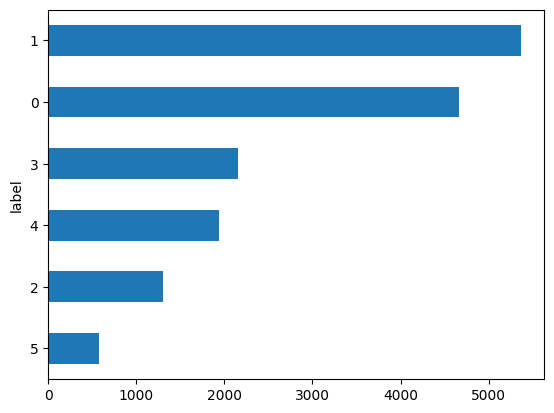

In [24]:
import matplotlib.pyplot as plt

df["label"].value_counts(ascending=True).plot.barh()
plt.show()

<a id="18.6.2-applying-a-tokenizer-to-a-dataset"></a>

### 18.6.2 Applying a Tokenizer to a Dataset

Let's show next how we can use the DistilBERT tokenizer from Section 18.5 to convert the first 5 samples in the training dataset to sequences of tokens. Since in the previous cells we set the format of the dataset to `pandas`, we need to first reset the format to the default (`type=None`), so that the dataset returns Python objects again.

In [25]:
emotions.set_format(type=None)

training_samples_5 = emotions["train"][:5]
training_samples_5

{'text': ['i didnt feel humiliated',
  'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake',
  'im grabbing a minute to post i feel greedy wrong',
  'i am ever feeling nostalgic about the fireplace i will know that it is still on the property',
  'i am feeling grouchy'],
 'label': [0, 0, 3, 2, 3]}

Let's extract only the text data, and not the labels.

In [26]:
text_training_5 = training_samples_5['text']
text_training_5

['i didnt feel humiliated',
 'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake',
 'im grabbing a minute to post i feel greedy wrong',
 'i am ever feeling nostalgic about the fireplace i will know that it is still on the property',
 'i am feeling grouchy']

The next cell applies the tokenizer and displays the sequence of tokens. The argument `padding=True` pads the shorter messages to the length of the longest message.

In [27]:
output_tokens_6 = tokenizer(text_training_5, padding=True)

print("Input IDs")
for item in output_tokens_6.input_ids:
    print(item)

print("Attention Mask")
for item in output_tokens_6.attention_mask:
    print(item)

Input IDs
[101, 1045, 2134, 2102, 2514, 26608, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[101, 1045, 2064, 2175, 2013, 3110, 2061, 20625, 2000, 2061, 9636, 17772, 2074, 2013, 2108, 2105, 2619, 2040, 14977, 1998, 2003, 8300, 102]
[101, 10047, 9775, 1037, 3371, 2000, 2695, 1045, 2514, 20505, 3308, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[101, 1045, 2572, 2412, 3110, 16839, 9080, 12863, 2055, 1996, 13788, 1045, 2097, 2113, 2008, 2009, 2003, 2145, 2006, 1996, 3200, 102, 0]
[101, 1045, 2572, 3110, 24665, 7140, 11714, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Attention Mask
[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


<a id="18.7-models"></a>

## 18.7 Models

In this section, we will work with pretrained models directly. We will load a pretrained model and fine-tune the model on our dataset.

<a id="18.7.1-importing-a-pretrained-model"></a>

### 18.7.1 Importing a Pretrained Model

Similarly to using the `AutoTokenizer` to load the tokenizer for `"distilbert-base-uncased"` in the above section, the `AutoModelForSequenceClassification` class can be used to load the model to perform sequence classification based on a given checkpoint name.

In the next cell, `AutoModelForSequenceClassification` is used with the `from_pretrained()` method to load a pretrained checkpoint of the DistilBERT model. The argument `num_labels=6` adds a classification layer with 6 outputs (one for each emotion) on top of the pretrained model. The cell output indicates that the parameters of the classification layers were newly initialized and they are listed as `MISSING` from the pretrained checkpoint. This is expected, as we will fine-tune the model on the emotions dataset.

In [28]:
from transformers import AutoModelForSequenceClassification

model_ckpt = "distilbert-base-uncased"
model = AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels=6)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The loaded model is a regular PyTorch `nn.Module`. We can check this in the next cell and count its parameters. We can see that the DistilBERT model has about 66 million parameters.

In [29]:
import torch
import torch.nn as nn

print("Is nn.Module:", isinstance(model, nn.Module))
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

Is nn.Module: True
Number of parameters: 66958086


Let's also examine the model's architecture. It consists of an embeddings layer with token embeddings for the 30,522 tokens in the vocabulary, and a stack of 6 Transformer encoder blocks. On top of them is a classification head with 6 output neurons, since the dataset has 6 categories of messages. We will study Transformer Networks in Lecture 19.

In [30]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


<a id="18.7.2-fine-tuning-a-pretrained-model"></a>

### 18.7.2 Fine-tuning a Pretrained Model

This section explains how to fine-tune the DistilBERT model to the Emotions dataset.

#### Dataset Preparation

First, let's use the tokenizer for the `"distilbert-base-uncased"` model that we downloaded earlier to tokenize the emotions dataset. To do that, we will define a function `tokenize` which applies the `tokenizer` to `rows['text']`, i.e., the tokenizer will be applied only to the text features in the dataset that pertain to the Twitter messages, and not to the label features. The argument `truncation=True` indicates to truncate long sentences in the training data that exceed the maximum number of tokens (for DistilBERT it is set to 512 tokens).

In the next line, the `emotions.map()` method applies the `tokenize` function to the samples in the dataset. The option `batched=True` instructs to apply the tokenization to a batch of input sequences instead of to each text sequence individually, which speeds up the tokenization.

In [31]:
def tokenize(rows):
    return tokenizer(rows['text'], truncation=True)

tokenized_datasets = emotions.map(tokenize, batched=True)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Let's extract the train, validation, and test datasets and assign individual variable names to each of them.

In [32]:
tokenized_train_dataset = tokenized_datasets["train"]
tokenized_val_dataset = tokenized_datasets["validation"]
tokenized_test_dataset = tokenized_datasets["test"]

In [33]:
# Check the tokenized train dataset
tokenized_train_dataset

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 16000
})

In [34]:
# Check the first sample
tokenized_train_dataset[0]

{'text': 'i didnt feel humiliated',
 'label': 0,
 'input_ids': [101, 1045, 2134, 2102, 2514, 26608, 102],
 'token_type_ids': [0, 0, 0, 0, 0, 0, 0],
 'attention_mask': [1, 1, 1, 1, 1, 1, 1]}

Note in the output of the last cell that the tokenized sequences for the first sample are not padded. In Hugging Face, `DataCollatorWithPadding` pads the tokenized input samples during batch preparation to have the same length, i.e., it pads each sentence to the maximum length in each batch. That is, if the longest sentence in a batch has 60 tokens, then all other sentences in that batch will be padded with 0's to have 60 tokens. This is referred to as *dynamic padding*, and it is more efficient than padding each sequence to a fixed length (e.g., 512 is the maximum length in DistilBERT), because it only pads as much as necessary. By passing the tokenizer to `DataCollatorWithPadding`, the function can handle specific padding requirements, such as special tokens used with the DistilBERT model.

In [35]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

#### Model Training

Now, we are ready to fine-tune the model.

The Transformers library in Hugging Face provides a `Trainer` class for model training, which is similar to `model.fit` in Keras-TensorFlow. That is, we just need to pass all parameters that are needed for training, and afterwards run `Trainer.train()` to fit the model to the data. The input parameters are first defined with the class `TrainingArguments` as shown in the next cell. In this case, the Training Arguments include the output directory to save the training outputs, evaluation strategy, optimizer, learning rate, batch sizes for training and validation, number of training epochs, weight decay, and whether to report the results to external tools.

In [36]:
from transformers import TrainingArguments

# Define training arguments for the model
training_args = TrainingArguments(
    # Directory to save model checkpoints and logs
    output_dir="bert-emotion",
    # Evaluation strategy - evaluate the model at the end of each epoch
    eval_strategy="epoch",
    # Optimizer to use (Adam with weight decay)
    optim="adamw_torch",
    # Learning rate for the optimizer
    learning_rate=2e-5,
    # Batch size for training
    per_device_train_batch_size=16,
    # Batch size for evaluation
    per_device_eval_batch_size=16,
    # Number of training epochs
    num_train_epochs=2,
    # Weight decay to apply for regularization
    weight_decay=0.01,
    # Disable reporting to external tools (e.g., WandB, TensorBoard)
    report_to="none"
)

We will also define a function called `compute_metrics` to calculate the accuracy at the end of each epoch.

In [37]:
from sklearn.metrics import accuracy_score

# Function to compute metrics during training
def compute_metrics(eval_pred):
    outputs, labels = eval_pred
    predictions = outputs.argmax(axis=-1)
    acc = accuracy_score(labels, predictions)
    return {"accuracy": acc}

Next, we will define our `trainer` as an instance of the `Trainer` class by passing the model that we defined, the training arguments, the training and validation datasets, tokenizer, data collator, and the function for computing performance metrics (accuracy). Afterward, we will initialize the training by running `trainer.train()` as in the following cell. We can see that the loss and accuracy values are reported after each epoch.

In [38]:
from transformers import Trainer

# Initialize the Trainer with the required parameters
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train_dataset,
    eval_dataset=tokenized_val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [39]:

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.258728,0.196039,0.922000
2,0.148987,0.152855,0.938500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2000, training_loss=0.32154589462280275, metrics={'train_runtime': 278.4533, 'train_samples_per_second': 114.921, 'train_steps_per_second': 7.183, 'total_flos': 389287358125632.0, 'train_loss': 0.32154589462280275, 'epoch': 2.0})

The training took about 5 minutes, and after 2 epochs, the model reached a validation accuracy of 93.85%.

#### Model Evaluation

Next, let's evaluate the model performance on the test dataset. The calculated accuracy is 92.35%.

In [40]:
# Evaluate the model on the test dataset
test_metrics = trainer.evaluate(eval_dataset=tokenized_test_dataset)

# Print the evaluation metrics
print(test_metrics)

Training Loss,Validation Loss,Epoch,Accuracy
0.148987,0.173903,2,0.923500


{'eval_loss': 0.17390252649784088, 'eval_accuracy': 0.9235}


In addition, let's predict the class labels for the four sentences shown below. First, we will need to apply the tokenizer to prepare the sentences, and move the inputs to the same device as the model (e.g., to the GPU, if available).

In [41]:
# List of sentences to evaluate
test_texts = ["I feel fantastic!", "I'm a bit sad today.", "This is so exciting!", "I was shocked by the news."]

# Tokenize the sentences, pad them to the same length for batch processing
inputs = tokenizer(test_texts, return_tensors="pt", padding=True, truncation=True).to(model.device)
inputs

{'input_ids': tensor([[  101,  1045,  2514, 10392,   999,   102,     0,     0,     0,     0],
        [  101,  1045,  1005,  1049,  1037,  2978,  6517,  2651,  1012,   102],
        [  101,  2023,  2003,  2061, 10990,   999,   102,     0,     0,     0],
        [  101,  1045,  2001,  7135,  2011,  1996,  2739,  1012,   102,     0]],
       device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 0]], device='cuda:0')}

In the next cell, we pass the inputs to the model, and use `argmax` to calculate the predicted labels for the sentences.

In [42]:
# Forward pass through the model
outputs = model(**inputs)

# Get predicted labels for each sentence
predicted_labels = outputs.logits.argmax(axis=-1).cpu().tolist()
print("Predicted Labels:", predicted_labels)

Predicted Labels: [1, 0, 1, 5]


To understand the predicted labels, let's retrieve the class names, and print the sentences with the class names of the predicted labels.

In [43]:
# Emotion class names
class_names = emotions["train"].features["label"].names
class_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [44]:
# Print results
for text, label in zip(test_texts, predicted_labels):
    print(f"Text: '{text}'; Predicted Label: {class_names[label]}")

Text: 'I feel fantastic!'; Predicted Label: joy
Text: 'I'm a bit sad today.'; Predicted Label: sadness
Text: 'This is so exciting!'; Predicted Label: joy
Text: 'I was shocked by the news.'; Predicted Label: surprise


<a id="18.8-text-generation-strategies"></a>

## 18.8 Text Generation Strategies

This section covers strategies for text generation with pretrained models that include **search-based methods** and **sampling-based methods**.

The DistilBERT model that we used in this lecture is an encoder model, which extracts representations of the input text, and it can be used for text classification or other NLP tasks, but it cannot generate text. For text generation we need a *causal language model*, which predicts the next token based on the previous tokens (explained in Lecture 19).

Let's use the GPT-2 language model, and we will also need to use the corresponding tokenizer for GPT-2. The argument `pad_token_id` is optional, and its purpose is to define the id of the token used for padding the text sequences. In this case, the id of the padding token is set to the id of the end-of-sequence token (`eos_token_id`), which is a common choice for language models that do not have a dedicated padding token.

In [45]:
from transformers import GPT2LMHeadModel
from transformers import GPT2Tokenizer

gen_tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

gen_model = GPT2LMHeadModel.from_pretrained("gpt2", pad_token_id=gen_tokenizer.eos_token_id)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

To generate text with a pretrained language model using the Hugging Face library, we will use the `generate()` method of the model. The generation process involves making several choices, each with its own set of advantages and trade-offs. Based on the selected generation strategy, the model output can vary significantly.

<a id="18.8.1-search-based-methods"></a>

### 18.8.1 Search-based Methods

Two common search-based methods for generating text with language models are:

 - **Greedy search** selects the word with the highest probability as the next word. The major drawback of greedy search is that it can miss potentially high-probability words that follow a low-probability word. Therefore, although each individual word may be the best fit when generating a response, the entire generated text can be less relevant for the query.
 - **Beam search** selects a sequence of words (beam) that has the overall highest probability. This approach reduces the risk of missing high-probability words, because rather than focusing only on the next word in a sequence, beam search looks at the probability of the entire response.

Beam search is typically preferred over greedy search, because the model can consider multiple routes and find the best option. For example, in the following figure, the input query to the model is "The Financial Times is ...". The model created four possible beams with a potential response, and out of the four beams, the third beam "a newspaper founded in 1888" was selected as the most coherent human-like response.

<img src='images/beam_search.png' width=500px>

*Figure: Beam search example.* Source: [link](https://ig.ft.com/generative-ai/)

Let's consider the sentence `input_string` in the next cell. We will first preprocess it with the tokenizer to encode it into a sequence of integers. The argument `return_tensors="pt"` specifies that the output should be returned as PyTorch tensors, where `"pt"` stands for PyTorch. This argument is required when we plan to pass the tokenized sequence to a PyTorch model.

In [46]:
input_string = "Yesterday I spent several hours in the library, studying"
input_tokens = gen_tokenizer(input_string, return_tensors="pt")

In [47]:
# Check the tokenized sequence
input_tokens

{'input_ids': tensor([[28065,   314,  3377,  1811,  2250,   287,   262,  5888,    11, 11065]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

Next, we will use the GPT-2 model for text generation with the `generate()` method, to generate text that continues the input sentence. The argument `max_length` tells the model to generate 64 tokens or less (including the tokens of the input sentence), and `**input_tokens` is used to unpack the dictionary `input_tokens` (recall from Lecture 3 on calling a function with two asterisks `**`). In this case, `input_tokens` is a dictionary with keys `'input_ids'` and `'attention_mask'`.

Afterward, we use the tokenizer with the `decode()` method to convert the generated sequence of token ids back into a text string.

By default, `generate()` uses *greedy search* and at each step, it selects the token with the highest probability. Notice the repetitions in the generated text below (e.g., of the sentence "I was amazed at how much I had learned"). Greedy search tends to produce such repetitive text, since the model keeps choosing the same high-probability continuation, and it can get stuck in a loop.

In [48]:
output_greedy = gen_model.generate(**input_tokens, max_length=64)

print(gen_tokenizer.decode(output_greedy[0], skip_special_tokens=True))

Yesterday I spent several hours in the library, studying the books, and I was amazed at how much I had learned. I was amazed at how much I had learned. I was amazed at how much I had learned. I was amazed at how much I had learned. I was amazed at how much I had learned.


Next, let's apply a beam search strategy to the same input. This is shown in the following cell, where beam search examines multiple probable solutions (beams) for the generated text, whose number is set by the argument `num_beams=32`. We also prevented the model from repeating any pair of consecutive words with the argument `no_repeat_ngram_size=2`. By considering several possible solutions, the beam search algorithm tries to improve the text generated by the model.

In [49]:
output_beam = gen_model.generate(**input_tokens, max_length=64, num_beams=32, no_repeat_ngram_size=2)

print(gen_tokenizer.decode(output_beam[0], skip_special_tokens=True))

Yesterday I spent several hours in the library, studying all the books I could get my hands on, and trying to figure out what I wanted to do with them. I didn't know what to expect, but I did know that it was going to be a lot of fun.

When I got home, I


<a id="18.8.2-sampling-based-methods"></a>

### 18.8.2 Sampling-based Methods

Besides search-based methods, such as greedy search and beam search which aim to find the best sequence of tokens that maximizes the likelihood of the generated text, modern language models also employ **sampling-based methods** that introduce controlled randomness to generate more diverse and creative text. Instead of always choosing the most likely tokens, these methods sample from the model's probability distribution, allowing for variability in the generated output.

Sampling-based methods are especially useful for tasks like creative writing, dialogue generation, and open-ended text completion.

Sampling-based strategies include the following.

1. Temperature Sampling

**Temperature** controls the randomness of predictions by scaling the logits (raw prediction scores) before the softmax activation function in the output layer. A typical default temperature value is 1.0. Lower temperature values in the range 0.1 - 0.7 make the model more confident and deterministic, whereas higher temperature values in the range 1.0 - 2.0 increase randomness and creativity in the generated text.

The next example shows two different responses with a low and high temperature. The argument `do_sample=True` specifies that the model should sample from the probability distribution of possible next tokens.

In [50]:
input_string = "The secret door opened, revealing"
input_tokens = gen_tokenizer(input_string, return_tensors="pt")

In [51]:
# Low temperature - more focused and deterministic
output_low_temp = gen_model.generate(**input_tokens, max_length=80, do_sample=True, temperature=0.3)

# High temperature - more random and creative
output_high_temp = gen_model.generate(**input_tokens, max_length=80, do_sample=True, temperature=1.5)

print("Low Temperature Output:")
print(gen_tokenizer.decode(output_low_temp[0], skip_special_tokens=True))
print("\nHigh Temperature Output:")
print(gen_tokenizer.decode(output_high_temp[0], skip_special_tokens=True))

Low Temperature Output:
The secret door opened, revealing a young man, who looked like he was about to leave. He was wearing a black jacket and black pants. He was wearing a black hat and black boots. He was wearing a black shirt and black pants. He was wearing a black hat and black pants. He was wearing a black hat and black pants. He was wearing a black hat and black pants. He

High Temperature Output:
The secret door opened, revealing one of King's best friends's younger brothers. The group found Jack, not one to be taken to a friend's apartment anymore, as I.O.'s were soon being placed out on social-networking sites as well. The world was about the same age that King had been.

Jack turned two the following morning, with that revelation that he loved


2. Top-K Sampling

**Top-K sampling** limits the model to selecting from only the K most likely next tokens at each step. At each generation step, the model keeps only the top K tokens (those with the highest probability), and samples randomly from this reduced set of tokens. Instead of selecting the token with the highest probability as in greedy search, top-K sampling considers several most likely tokens at each step.

A typical default value for K is 50. Small K values in the range 10-20 result in more focused but less diverse responses, and large K values over 100 produce more diverse but potentially less coherent text.

In [52]:
# Top-K sampling with K=10
output_low_topk = gen_model.generate(**input_tokens, max_length=80, do_sample=True, top_k=10)

# Top-K sampling with K=100
output_high_topk = gen_model.generate(**input_tokens, max_length=80, do_sample=True, top_k=100)

print("Low Top-K Output:")
print(gen_tokenizer.decode(output_low_topk[0], skip_special_tokens=True))
print("\nHigh Top-K Output:")
print(gen_tokenizer.decode(output_high_topk[0], skip_special_tokens=True))

Low Top-K Output:
The secret door opened, revealing that the woman had come out of the closet and was looking for help in the office.

"What happened here?" asked the female officer, as the officers looked down.

"She went to a place to get some food," replied the male officer. "She came to this room and was told that there were four other officers. She came to the

High Top-K Output:
The secret door opened, revealing a dozen guests.

"Hey, it looks like you got a question," he said for one of them, then led the group to his office. He gave one of the guests an important bag of green tea and a glass of orange juice. "I'm sorry, sir, but there's nothing we can change."

The room cleared to reveal another


3. Top-P (Nucleus) Sampling

**Top-P sampling** (also called nucleus sampling) selects the smallest set of tokens whose cumulative probability exceeds a chosen threshold P. It ranks all tokens by probability and samples from a reduced "nucleus" of tokens with cumulative probability greater than P.

When the model is confident, fewer tokens are considered, and when the model is uncertain, more tokens are included. A typical default value for P is 0.9. Lower values for P in the range 0.5-0.7 produce more deterministic and focused outputs, while higher values for P in the range 0.95-1.0 result in more diverse and creative outputs.

In [53]:
# Top-P sampling with P=0.5
output_low_topp = gen_model.generate(**input_tokens, max_length=80, do_sample=True, top_p=0.5)

# Top-P sampling with P=0.95
output_high_topp = gen_model.generate(**input_tokens, max_length=80, do_sample=True, top_p=0.95)

print("Low Top-P Output:")
print(gen_tokenizer.decode(output_low_topp[0], skip_special_tokens=True))
print("\nHigh Top-P Output:")
print(gen_tokenizer.decode(output_high_topp[0], skip_special_tokens=True))

Low Top-P Output:
The secret door opened, revealing the young woman, who had been wearing a blue and white T-shirt, and wearing a pink T-shirt.

"What are you doing here?" the young woman asked.

"I'm here to talk to you about my life," the young woman said.

"Oh, I see. I'm a teacher here," the young woman

High Top-P Output:
The secret door opened, revealing a huge, massive-looking man behind a huge counter that looked like it could be a gigantic alien body. From a tall table it looked as if it belonged to a colossal planet. A huge, black-robed man could be seen in the middle of the room, with his arms hanging out in front of him. With one arm there was a huge red star


It is also possible to combine different sampling methods as in the next example.

In [54]:
# Combination: top_k=60, top_p=0.95, temperature=1.5
output = gen_model.generate(**input_tokens, max_length=80, do_sample=True, top_k=60, top_p=0.95, temperature=1.5)

print(gen_tokenizer.decode(output[0], skip_special_tokens=True))

The secret door opened, revealing its usual warm skin at the sides, its light and fluffy feet.

He moved up the staircase to the large chair outside the main meeting room—a corner was where they sat when he stood before them… I'll see if he could stay inside for a little while, after meeting you first, when they left… I'll tell him if his friend will need


Other parameters in `model.generate()` include:

- `repetition_penalty`: Discourages the model from repeating the same tokens or phrases. Values > 1.0 penalize repetition, and values of 1.2-1.5 or higher reduce repetition more aggressively.
- `length_penalty`: Controls the model's preference for longer or shorter sequences (mainly used with beam search). Values < 1.0 favor shorter responses, and values > 1.0 favor longer responses.
- `no_repeat_ngram_size`: Prevents repeating any n-gram of the specified size. We used it above in the beam search example.
- `min_length` and `max_length`: Define the minimum and maximum number of tokens in the generated text.

Recommendations for text generation:

- Use lower temperature for factual tasks, and higher temperature for creative tasks.
- Enable `do_sample=True` when using temperature, top-K, or top-P sampling.
- Start with default values, such as `top_p=0.9`, `temperature=1.0`, and `top_k=50`.
- Use `repetition_penalty` to avoid loops and repetitive phrases, especially with smaller models.
- Combine sampling methods `top_k`, `top_p`, and `temperature` for better control of diversity and coherence.
- Generate multiple sequences with `num_return_sequences` and select the best one.

While search-based methods were commonly used with older NLP models for tasks with a single correct output, modern LLMs mostly rely on sampling-based methods, usually with temperature combined with top-P, and sometimes top-K. Most APIs for LLMs default to a temperature around 0.7–1.0.

<a id="18.9-nlp-pipelines"></a>

## 18.9 NLP Pipelines

The simplest way to use a pretrained model from Hugging Face is through the **Pipelines** API, which allows us to perform a variety of NLP tasks with a few lines of code through the `pipeline()` function. A pipeline bundles together a tokenizer that preprocesses the input text, a pretrained model, and the postprocessing of the model outputs into a readable result.

The `pipeline()` function has the following syntax:

```
from transformers import pipeline

# Pipeline to use a default model & tokenizer for a given task
pipeline("<task-name>")

# Pipeline to use an existing or custom model
pipeline("<task-name>", model="<model_name>")

# Pipeline to use an existing or custom model and tokenizer
pipeline("<task-name>", model="<model_name>", tokenizer="<tokenizer_name>")
```

Among the currently available task pipelines are:

- Sentiment analysis
- Text generation
- NER (named entity recognition)
- Zero-shot classification
- Fill mask

The pipelines for question answering, translation, and summarization were removed in version 5 of the Transformers library, and these tasks are now performed with the text generation pipeline and chat models, which are covered in Lecture 20.

In the following subsections, we will examine examples of using the `pipeline("<task-name>")` function with different NLP tasks. As we mentioned, if we don't provide the names of the model and tokenizer, the pipeline will assign a default model and tokenizer for the task, and it will download the model parameters and other required files from the Hugging Face Hub.

In [55]:
from transformers import pipeline

<a id="18.9.1-sentiment-analysis"></a>

### 18.9.1 Sentiment Analysis

The first example uses `pipeline()` for sentiment analysis. Sentiment analysis is a text classification task, where the goal is to classify a text (e.g., a movie review) as positive or negative.

When the cell is executed, the pipeline will select a default pretrained model for sentiment analysis in English, it will download the model and the related tokenizer, and it will instantiate a text classifier object. In this case, we can see in the cell output that the default pretrained model used is `distilbert-base-uncased-finetuned-sst-2-english`. The argument `device=0` in the pipeline assigns the pipeline to a GPU device if it is available. For running the model on CPU, use `device=-1`.

In [56]:
classifier = pipeline("sentiment-analysis", device=0)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In the next cell, the classifier is applied to a sentence. The output is the predicted label and the confidence score.

In [57]:
classifier("I fully understand what you are saying.")

[{'label': 'POSITIVE', 'score': 0.9996806383132935}]

The pipeline allows passing multiple sentences, and it will return a sentiment label and confidence score for each sentence.

In [58]:
classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
)

[{'label': 'POSITIVE', 'score': 0.9598046541213989},
 {'label': 'NEGATIVE', 'score': 0.9994558691978455}]

A pipeline can also be created from a model and a tokenizer that we loaded or fine-tuned ourselves, by passing them as the `model` and `tokenizer` arguments. The next cell creates a text classification pipeline from the DistilBERT model that we fine-tuned on the Emotions dataset in Section 18.7.2.

In [60]:
# Text classification pipeline with our fine-tuned model
our_classifier = pipeline("text-classification", model=model, tokenizer=tokenizer, device=0)

our_classifier(["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"])

[{'label': 'LABEL_2', 'score': 0.31614208221435547},
 {'label': 'LABEL_3', 'score': 0.9504706859588623}]

<a id="18.9.2-text-generation"></a>

### 18.9.2 Text Generation

In this example, we will use the `"text-generation"` pipeline to generate text that continues a provided prompt.

In [61]:
generator = pipeline("text-generation", device=0)

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/50.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/289 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

Now let's provide a prompt text to the generator object, and the generator will continue the text. The argument `max_new_tokens` sets the maximum number of tokens to generate after the prompt. Note that text generation involves randomness, so some of the outputs will not be perfect. And admittedly, this is one of the most difficult NLP tasks.

In [62]:
outputs_1 = generator("In this course, we will teach you how to", max_new_tokens=60)

print(outputs_1[0]['generated_text'])

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


In this course, we will teach you how to use the Python programming language to solve problems. Python is a popular language that is easy to learn and has a wide range of applications. Whether you're a beginner or an experienced programmer, this course will help you master Python and its many features.

We will cover the basics of Python, including data types


In [63]:
outputs_2 = generator("Niagara Falls is a city located in", max_new_tokens=60)

print(outputs_2[0]['generated_text'])

Niagara Falls is a city located in the province of Ontario, Canada. The city is situated on the Niagara River at the western end of Niagara Falls. The city is a major tourist destination and is known for its waterfalls, which are among the most powerful waterfalls in the world. The city is also home to the famous Clifton


<a id="18.9.3-named-entity-recognition"></a>

### 18.9.3 Named Entity Recognition
Named Entity Recognition (NER), also known as named entity tagging, is a task of identifying parts of the input that represent entities. Examples of entities are:

- Locations (LOC)
- Organizations (ORG)
- Persons (PER)
- Miscellaneous entities (MISC)

In [64]:
ner = pipeline("ner", device=0)

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

In [65]:
text_1 = "Abraham Lincoln was a president who lived in the United States."

print(ner(text_1))

[{'entity': 'I-PER', 'score': np.float32(0.998367), 'index': 1, 'word': 'Abraham', 'start': 0, 'end': 7}, {'entity': 'I-PER', 'score': np.float32(0.99942005), 'index': 2, 'word': 'Lincoln', 'start': 8, 'end': 15}, {'entity': 'I-LOC', 'score': np.float32(0.9996445), 'index': 10, 'word': 'United', 'start': 49, 'end': 55}, {'entity': 'I-LOC', 'score': np.float32(0.99965715), 'index': 11, 'word': 'States', 'start': 56, 'end': 62}]


Or, we can use Pandas to display the output.

In [66]:
import pandas as pd

pd.DataFrame(ner(text_1))

,entity,score,index,word,start,end
0,I-PER,0.998367,1,Abraham,0,7
1,I-PER,0.999420,2,Lincoln,8,15
2,I-LOC,0.999645,10,United,49,55
3,I-LOC,0.999657,11,States,56,62


In [67]:
text_2 = """BAGHDAD -- Archaeologists in northern Iraq last week unearthed 2,700-year-old rock carvings featuring war scenes and trees from the Assyrian Empire, an archaeologist said Wednesday.
    The carvings on marble slabs were discovered by a team of experts in Mosul, Iraq’s second-largest city, who have been working to restore the site of the ancient Mashki Gate, which was bulldozed by Islamic State group militants in 2016.
    Fadhil Mohammed, head of the restoration works, said the team was surprised by discovering “eight murals with inscriptions, decorative drawings and writings.”
    Mashki Gate was one of the largest gates of Nineveh, an ancient Assyrian city of this part of the historic region of Mesopotamia.
    The discovered carvings show, among other things, a fighter preparing to fire an arrow while others show palm trees.
    """

pd.DataFrame(ner(text_2))

,entity,score,index,word,start,end
0,I-LOC,0.434807,1,BA,0,2
1,I-LOC,0.999473,12,Iraq,38,42
2,I-MISC,0.893630,34,Assyrian,132,140
3,I-LOC,0.782092,35,Empire,141,147
4,I-LOC,0.999344,56,Mo,255,257
5,I-LOC,0.999132,57,##sul,257,260
6,I-LOC,0.999156,59,Iraq,262,266
7,I-LOC,0.975450,78,Ma,347,349
8,I-LOC,0.961386,79,##sh,349,351
9,I-LOC,0.963745,80,##ki,351,353


<a id="18.9.4-zero-shot-classification"></a>

### 18.9.4 Zero-shot Classification
Zero-shot classification is a task to classify text documents, where the term
*zero-shot* classification refers to tasks for which a language model has not been trained. That is, the model was not trained to classify documents using the provided type of labels in the next example.

In [68]:
classifier = pipeline("zero-shot-classification", device=0)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

The pipeline allows us to list `candidate_labels` to be used for the classification. For this example, the model returned confidence scores for each category, and the highest probability was assigned to the "sports" category.

In [69]:
classifier(
    "Peyton Manning became the first quarterback ever to lead two different teams to multiple Super Bowls.",
    candidate_labels=["education", "politics", "business", "sports"],
)

{'sequence': 'Peyton Manning became the first quarterback ever to lead two different teams to multiple Super Bowls.',
 'labels': ['sports', 'business', 'education', 'politics'],
 'scores': [0.9866245985031128,
  0.006729836110025644,
  0.003462165826931596,
  0.003183396067470312]}

<a id="18.9.5-mask-filling"></a>

### 18.9.5 Mask Filling
The pipeline with the `fill-mask` task is used to fill in blanks in an input text.

In [70]:
mask_filling = pipeline("fill-mask", device=0)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

We can provide the `top_k` argument to indicate the number of returned answers.

In [71]:
mask_filling("Abraham Lincoln was a <mask> who lived in the United States.", top_k=5)

[{'score': 0.3327236473560333,
  'token': 3661,
  'token_str': ' Democrat',
  'sequence': 'Abraham Lincoln was a Democrat who lived in the United States.'},
 {'score': 0.18090975284576416,
  'token': 1172,
  'token_str': ' Republican',
  'sequence': 'Abraham Lincoln was a Republican who lived in the United States.'},
 {'score': 0.03390646353363991,
  'token': 16495,
  'token_str': ' Jew',
  'sequence': 'Abraham Lincoln was a Jew who lived in the United States.'},
 {'score': 0.02841552160680294,
  'token': 24156,
  'token_str': ' Presbyterian',
  'sequence': 'Abraham Lincoln was a Presbyterian who lived in the United States.'},
 {'score': 0.02462913654744625,
  'token': 11593,
  'token_str': ' physician',
  'sequence': 'Abraham Lincoln was a physician who lived in the United States.'}]

In [72]:
mask_filling("Flooding on the Yangtze river remains serious although <mask> levels on parts of the river decreased today.", top_k=2)

[{'score': 0.2489064335823059,
  'token': 514,
  'token_str': ' water',
  'sequence': 'Flooding on the Yangtze river remains serious although water levels on parts of the river decreased today.'},
 {'score': 0.12597206234931946,
  'token': 11747,
  'token_str': ' oxygen',
  'sequence': 'Flooding on the Yangtze river remains serious although oxygen levels on parts of the river decreased today.'}]

Pipelines are convenient when a pretrained model solves our task as-is. Internally, each pipeline applies the tokenizer, the model, and the postprocessing of the outputs that we worked with in the previous sections.

<a id="appendix:-emotion-classification-with-an-embedding-model"></a>

## Appendix: Emotion Classification with an Embedding Model

**The material in the Appendix is not required for quizzes and assignments.**

In this appendix, we define and train a simple model for classification of the messages in the Emotions dataset, using the word embeddings introduced in Section 18.3.2. The model uses an embedding layer to project the tokens in each message into 8-dimensional vectors. The embedding vectors of the 64 tokens in a message are flattened into one vector, which is further processed through fully-connected layers, and the last layer predicts the emotion of the message. The model is similar to the models in Lecture 15, and it is defined as a subclass of `nn.Module`.

The word embeddings are implemented with the `nn.Embedding` layer in PyTorch, which maps each token index to a trainable vector. The layer can be considered as a look-up table, i.e., a trainable weight matrix with one row of size `embedding_dim` for each of the `num_embeddings` tokens in the vocabulary. During training, the embedding vectors are updated, so that tokens that are similar for the task get closer in the embedding space.

A few details about the model:

- `num_embeddings` is set to the vocabulary size of the tokenizer (30,522 tokens), since the input ids produced by the tokenizer are indices into this vocabulary.
- `padding_idx=0` tells the embedding layer that index 0 is the padding token `[PAD]`, so its embedding vector is fixed to zeros and padding does not contribute to the predictions.
- By default, PyTorch initializes the embedding vectors with values drawn from a standard normal distribution, which is a rather large scale for 512 values that are flattened and fed into a linear layer, and it slows down the training considerably. We therefore initialize the embedding vectors with small random values in the range [-0.05, 0.05], using the `nn.init` module.
- The last layer has 6 outputs, one for each emotion, and we will train the model with the cross-entropy loss.

In [73]:
class EmbeddingClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=8, seq_length=64, hidden_dim=32, num_classes=6):
        super().__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0)
        nn.init.uniform_(self.embedding.weight, -0.05, 0.05)
        self.embedding.weight.data[0] = 0                        # keep the padding vector at zero
        self.flatten = nn.Flatten()
        self.dense = nn.Linear(seq_length * embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.output = nn.Linear(hidden_dim, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)     # (batch, 64) -> (batch, 64, 8)
        x = self.flatten(x)               # (batch, 64, 8) -> (batch, 512)
        x = self.dropout(self.relu(self.dense(x)))
        return self.output(x)             # (batch, 6)

model = EmbeddingClassifier(vocab_size=tokenizer.vocab_size)
print(model)

EmbeddingClassifier(
  (embedding): Embedding(30522, 8, padding_idx=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense): Linear(in_features=512, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (output): Linear(in_features=32, out_features=6, bias=True)
)


The model has about 260,000 parameters, most of which are in the embedding layer (30,522 tokens x 8 dimensions). Let's also set the device for training, and move the model to it.

In [74]:
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

torch_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(torch_device)

Number of parameters: 260790


EmbeddingClassifier(
  (embedding): Embedding(30522, 8, padding_idx=0)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense): Linear(in_features=512, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (output): Linear(in_features=32, out_features=6, bias=True)
)

The model requires all messages to have the same length of 64 tokens, since the embedding vectors of the tokens are flattened into one vector. The messages in the dataset are short (20 tokens on average), and just a few of them are longer than 64 tokens. Therefore, we tokenize the messages again, now with `padding="max_length"`, which pads the shorter messages with the padding token up to 64 tokens, and truncates the longer messages.

To iterate over the data in batches, we will use PyTorch `DataLoader` objects. The `set_format("torch", ...)` method of the dataset returns the selected columns as PyTorch tensors, and a Hugging Face `Dataset` can be passed directly to a `DataLoader`.

In [75]:
from torch.utils.data import DataLoader

# Tokenize the messages with padding to a fixed length of 64 tokens
def tokenize_padded(rows):
    return tokenizer(rows["text"], truncation=True, padding="max_length", max_length=64)

padded_emotions = emotions.map(tokenize_padded, batched=True)
padded_emotions.set_format("torch", columns=["input_ids", "attention_mask", "label"])

train_dataloader = DataLoader(padded_emotions["train"], shuffle=True, batch_size=128)
test_dataloader = DataLoader(padded_emotions["test"], shuffle=False, batch_size=256)

# Inspect one batch
batch = next(iter(train_dataloader))
print(batch["input_ids"].shape, batch["label"].shape)

Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

torch.Size([128, 64]) torch.Size([128])


The training loop is the same as in Lecture 15: for each batch, we perform a forward pass, calculate the loss, perform a backward pass, and update the parameters. After each epoch, we evaluate the accuracy on the test set with `torch.no_grad()`.

In [76]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def evaluate(model, dataloader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch["input_ids"].to(torch_device)
            labels = batch["label"].to(torch_device)
            outputs = model(input_ids)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return correct / total

epoch_num = 10
for epoch in range(epoch_num):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for batch in train_dataloader:
        input_ids = batch["input_ids"].to(torch_device)
        labels = batch["label"].to(torch_device)

        optimizer.zero_grad()                 # reset the gradients
        outputs = model(input_ids)            # forward pass
        loss = criterion(outputs, labels)     # loss calculation
        loss.backward()                       # backward pass
        optimizer.step()                      # parameters update

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    test_accuracy = evaluate(model, test_dataloader)
    print(f"Epoch {epoch+1}/{epoch_num} - loss: {running_loss/total:.4f} - accuracy: {correct/total:.4f} - validation accuracy: {test_accuracy:.4f}")

Epoch 1/10 - loss: 1.7083 - accuracy: 0.2431 - validation accuracy: 0.3465
Epoch 2/10 - loss: 1.5194 - accuracy: 0.3485 - validation accuracy: 0.4245
Epoch 3/10 - loss: 1.2214 - accuracy: 0.5128 - validation accuracy: 0.6210
Epoch 4/10 - loss: 0.8978 - accuracy: 0.6660 - validation accuracy: 0.7010
Epoch 5/10 - loss: 0.6817 - accuracy: 0.7589 - validation accuracy: 0.7650
Epoch 6/10 - loss: 0.5406 - accuracy: 0.8227 - validation accuracy: 0.7960
Epoch 7/10 - loss: 0.4485 - accuracy: 0.8578 - validation accuracy: 0.8035
Epoch 8/10 - loss: 0.3728 - accuracy: 0.8862 - validation accuracy: 0.8065
Epoch 9/10 - loss: 0.3300 - accuracy: 0.8954 - validation accuracy: 0.8020
Epoch 10/10 - loss: 0.2931 - accuracy: 0.9056 - validation accuracy: 0.8085


This simple model, which only learns an embedding vector for each token and does not consider the order of the tokens beyond their positions in the flattened vector, reaches a test accuracy of about 80%. Note also that the training accuracy keeps increasing while the test accuracy stays at the same level, which indicates that the model starts overfitting.

Let's use the trained model to predict the emotion of the four sentences from the above section. The sentences are tokenized in the same way as the training data, with padding and truncation to 64 tokens.

In [77]:
new_texts = ["I feel fantastic!", "I'm a bit sad today.", "This is so exciting!", "I was shocked by the news."]

inputs = tokenizer(new_texts, truncation=True, padding="max_length", max_length=64, return_tensors="pt")

model.eval()
with torch.no_grad():
    outputs = model(inputs["input_ids"].to(torch_device))
    probabilities = torch.softmax(outputs, dim=1)

class_names = emotions["train"].features["label"].names
for text, probs in zip(new_texts, probabilities):
    print(f"{class_names[probs.argmax()]} ({probs.max():.3f}): {text}")

joy (0.997): I feel fantastic!
sadness (0.866): I'm a bit sad today.
joy (0.961): This is so exciting!
fear (0.598): I was shocked by the news.


## References

1. Complete Machine Learning Package, Jean de Dieu Nyandwi, available at [https://github.com/Nyandwi/machine_learning_complete](https://github.com/Nyandwi/machine_learning_complete).
2. Deep Learning with Python, Francois Chollet, Second Edition, Manning Publications, 2021.
3. Hugging Face LLM Course, available at [https://huggingface.co/learn/llm-course/chapter1/1](https://huggingface.co/learn/llm-course/chapter1/1).
4. Applications of Deep Neural Networks, Course at Washington University in St. Louis, Jeff Heaton, available at [https://github.com/jeffheaton/t81_558_deep_learning/blob/master/t81_558_class_11_01_huggingface.ipynb](https://github.com/jeffheaton/t81_558_deep_learning/blob/master/t81_558_class_11_01_huggingface.ipynb).
5. Getting Started with Hugging Face Transformers for NLP, Exxact Blog, available at [https://www.exxactcorp.com/blog/Deep-Learning/getting-started-hugging-face-transformers](https://www.exxactcorp.com/blog/Deep-Learning/getting-started-hugging-face-transformers).
6. An Introduction to Using Transformers and Hugging Face, Zoumana Kelta, available at [https://www.datacamp.com/tutorial/an-introduction-to-using-transformers-and-hugging-face](https://www.datacamp.com/tutorial/an-introduction-to-using-transformers-and-hugging-face).
7. Text generation strategies, Hugging Face Transformers documentation, available at [https://huggingface.co/docs/transformers/generation_strategies](https://huggingface.co/docs/transformers/generation_strategies).
8. SmolLM3 model card, Hugging Face, available at [https://huggingface.co/HuggingFaceTB/SmolLM3-3B](https://huggingface.co/HuggingFaceTB/SmolLM3-3B).
9. CARER: Contextualized Affect Representations for Emotion Recognition (the Emotions dataset), E. Saravia et al., EMNLP 2018, available at [https://aclanthology.org/D18-1404/](https://aclanthology.org/D18-1404/).

[BACK TO TOP](#top)